
# 05 深度学习量化金融：核心笔记

> **本章要解决的问题**：深度学习在金融里到底能做什么、不能做什么？一个神经网络凭什么能“学会”期权定价公式？为什么同一个模型，回测很好、实盘很差？作为个人研究者，值不值得学深度学习？

## 本章导读

这是一本 0 基础读书笔记，对应 Andrew Green 的《Deep Learning in Quantitative Finance》（Wiley, 2024/2025）。主线可以压成三句话：

1. **神经网络就是一个“可调参数的函数”**：输入价格、波动率、特征，输出价格、概率或仓位；训练就是调参数让预测更接近答案；
2. **它擅长逼近复杂函数**，可用于定价、希腊字母、曲面、对冲、合成数据，但不解决“没有信号”；
3. **金融信噪比低、非平稳、容易泄漏**，所以最难的从来不是“搭网络”，而是“验证”。

本章不堆公式，代码全部用 **numpy + scikit-learn**（不装 TensorFlow/PyTorch），所有数据都是合成数据，只用于演示。

### 学习目标

- 给定“神经网络”这个词，能用自己的话说清神经元、层、激活函数、前馈网络和“万能逼近”的含义。
- 给定一个训练任务，能说清损失函数、反向传播、数据缩放、权重初始化、优化器各自解决什么问题。
- 给定训练集/测试集误差，能判断模型是欠拟合还是过拟合，并用 weight decay、early stopping、dropout、集成等手段处理。
- 给定一种网络结构（CNN/RNN/自编码器/生成模型），能说出它在金融里的典型用途与直觉。
- 给定一个金融应用（定价、希腊字母、对冲、曲面、合成数据），能判断适不适合用深度学习，并说出主要风险。
- 给定一个“回测很好”的模型，能列出至少四条需要检查的边界条件。

### 先修

会看收益率、波动率；知道“训练集/测试集”“回归/分类”的基本含义；会一点点 Python 即可。课程里的第 11 章（机器学习与向前滚动验证）、第 20 章（多重检验）、第 37 章（工具链）、第 38 章（流水线）可以当参考。

## 在量化研究中的位置

- **谁用**：衍生品定价/对冲研究员、量化研究员、做信号合成的策略团队、想用合成数据补样本的研究者。
- **输入**：价格/波动率/期权链数据、模拟路径、特征矩阵、标签。
- **输出**：定价/希腊字母/曲面预测、对冲策略、合成数据、异常检测结果。
- **在流程的哪一步**：在“特征与标签”之后、“回测与验证”之前；它是工具箱里的一类模型，不是流程本身。
- **失败模式**：数据泄漏、过拟合、信噪比误判、把合成数据上的完美结果当真实、算力/维护成本失控。
- **最小工作流**：定问题 → 造/取数据 → 切训练/验证/测试 → 训练 → 看误差与过拟合 → 样本外/滚动验证 → 再谈上线。

### 环境准备



In [1]:

import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from sklearn.decomposition import PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.neural_network import MLPRegressor
from sklearn.preprocessing import StandardScaler
import sklearn

warnings.filterwarnings("ignore", category=ConvergenceWarning)
plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "DejaVu Sans"]
plt.rcParams["axes.unicode_minus"] = False
print("sklearn", sklearn.__version__, "| numpy", np.__version__)


sklearn 1.9.1 | numpy 2.4.4



## 1. 深度学习是什么（0 基础版）

### 1.1 从“线性模型”到“神经网络”

最简单的模型是线性回归：$y = w_1x_1 + w_2x_2 + b$。它只能表达“输入怎么线性组合”。可现实里的关系往往非线性：期权价格对波动率不是线性的，波动率曲面是弯的，对冲比例对价格是 S 形的。

神经网络的做法是**把很多个“小线性模型 + 非线性开关”叠起来**：

1. **神经元**：先算加权和 $z=w^Tx+b$，再过一个非线性函数 $\sigma(z)$；
2. **层**：很多神经元并排成“隐藏层”，多层叠起来就是“深度”；
3. **激活函数**：ReLU（$\max(0,z)$，最常用）、tanh（平滑，−1 到 1）、sigmoid（0 到 1，常用于概率）；
4. **前馈网络（MLP）**：数据从输入层流向隐藏层再到输出层，没有回路。

**万能逼近定理**说：只要隐藏层足够宽（或足够深）、激活函数选得合适，神经网络可以任意精度逼近一大类连续函数。这是“深度学习能学 BS 公式”的理论底气，但它只说“存在这样的网络”，**没说“用你的数据和方法一定能找到”**。

### 1.2 回归还是分类

- **回归**：输出连续值，比如期权价格、波动率、预期收益、对冲比例；损失函数常用 MSE（均方误差）；
- **分类**：输出类别或概率，比如“涨/跌”“是否触发障碍”“违约/不违约”；损失函数常用交叉熵。

量化里两者都常见：定价、希腊字母、曲面是回归；方向预测、meta-label、信用事件是分类。**先想清楚输出是什么，再选损失函数**。

### 1.3 它和传统模型的分工

深度学习不是“更高级的线性回归”：它擅长**自动学习特征交互**，但需要更多数据与算力、可解释性差、在低信噪比数据上容易学噪声。所以实务里常见“**简单模型打底、深度模型补充**”：线性和树模型给可解释基准，网络用来逼近定价、曲面、对冲这类复杂函数。

---

## 2. 训练：网络怎么“学会”

### 2.1 前向传播、损失、反向传播

训练分四步：**前向传播**（逐层算到输出 $\hat y$）→ **算损失**（如 MSE $=\frac1n\sum(\hat y_i-y_i)^2$）→ **反向传播**（链式法则算每个参数的梯度）→ **更新参数**（$w \leftarrow w-\eta\nabla w$）。一句话：**前向算答案，反向算责任，按责任调参数**。

**Sobolev 训练**（原书 3.9）：损失不只惩罚函数值误差，还惩罚导数（如 delta、vega）误差；对“价格 + 希腊字母”都要准的定价模型，比只拟合价格更稳。

### 2.2 数据缩放与权重初始化

- **数据缩放**：特征量纲差太大（价格 100、波动率 0.2）会让梯度被大特征主导，标准做法是标准化，**且只能用训练集统计量**；
- **权重初始化**：参数不能全设 0；常用随机初始化，让每层输出方差稳定。

### 2.3 损失函数与优化器

- **MSE**：回归默认，对大误差惩罚重；金融里常配合相对误差/分位数误差；
- **交叉熵**：分类默认，输出经 sigmoid/softmax 变成概率；
- **优化器**：SGD 简单但抖；Momentum 加惯性减震荡；Adam 自适应学习率，是最常用的默认选择。

### 2.4 常见训练问题

| 现象 | 可能原因 | 处理 |
|---|---|---|
| 损失不降/变 NaN | 学习率太大或太小、数据没缩放、数值溢出 | 调学习率、标准化、裁剪梯度 |
| 训练好、测试差 | 过拟合 | 正则化、早停、加数据 |
| 深层网络学不动 | 梯度消失 | ReLU、BatchNorm、残差连接 |

**BatchNorm** 把每层激活值重新标准化，让深层网络更好训，代价是要固定“批”的统计量。

### 2.5 验证与交叉验证

训练集调参数、验证集调超参、测试集只在最后用一次；时间序列**不能随机打乱**，必须按时间切分，否则未来信息会泄漏。向前滚动验证见第 11 章。

### 2.6 代码：让 MLP 学 BS 定价

先生成一批 Black–Scholes 看涨期权样本，用 MLP 回归价格，看它能不能“不看公式、只从数据里学会定价”。



迭代 127 | 训练 MAE 0.1235 | 测试 MAE 0.1296 | 测试 RMSE 0.1774
平均相对误差 0.644% | R^2 0.99991
  便宜(低价)：n=792 MAE 0.0540 相对 3.38%
  中等：n=816 MAE 0.1071 相对 0.69%
  贵(高价)：n=792 MAE 0.2285 相对 0.52%


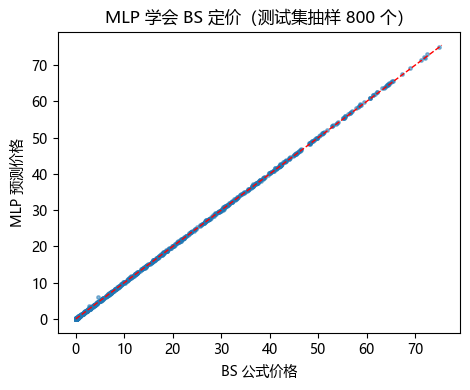

In [2]:

def bs_call(S, K, T, sigma, r=0.02):
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)
    return S * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)


def bs_delta(S, K, T, sigma, r=0.02):
    d1 = (np.log(S / K) + (r + 0.5 * sigma ** 2) * T) / (sigma * np.sqrt(T))
    return norm.cdf(d1)


rng = np.random.default_rng(5001)
N = 12000
S = rng.uniform(50, 150, N)
K = rng.uniform(80, 120, N)
T = rng.uniform(0.05, 2.0, N)
sig = rng.uniform(0.10, 0.60, N)
price = bs_call(S, K, T, sig)
X = np.column_stack([S, K, T, sig])
Xtr, Xte, ytr, yte = train_test_split(X, price, test_size=0.2, random_state=42)
scaler = StandardScaler().fit(Xtr)
Xtr_s, Xte_s = scaler.transform(Xtr), scaler.transform(Xte)
mlp = MLPRegressor(hidden_layer_sizes=(128, 128, 128), activation="relu", solver="adam",
                   alpha=1e-4, learning_rate_init=1e-3, max_iter=1500,
                   early_stopping=False, random_state=42)
mlp.fit(Xtr_s, ytr)
pred_te = mlp.predict(Xte_s)
print("迭代", mlp.n_iter_, "| 训练 MAE", round(float(np.abs(mlp.predict(Xtr_s) - ytr).mean()), 4),
      "| 测试 MAE", round(float(np.abs(pred_te - yte).mean()), 4),
      "| 测试 RMSE", round(float(np.sqrt(((pred_te - yte) ** 2).mean())), 4))
print("平均相对误差", f"{float(np.abs(pred_te - yte).mean() / yte.mean()):.3%}",
      "| R^2", round(float(mlp.score(Xte_s, yte)), 5))
low, high = np.quantile(yte, [0.33, 0.67])
for name, mask in [("便宜(低价)", yte <= low), ("中等", (yte > low) & (yte <= high)), ("贵(高价)", yte > high)]:
    print(f"  {name}：n={int(mask.sum())} MAE {np.abs(pred_te - yte)[mask].mean():.4f}"
          f" 相对 {np.abs(pred_te - yte)[mask].mean() / yte[mask].mean():.2%}")
fig, ax = plt.subplots(figsize=(4.8, 4))
ax.scatter(yte[:800], pred_te[:800], s=6, alpha=0.5)
ax.plot([0, yte.max()], [0, yte.max()], "r--", linewidth=1)
ax.set_xlabel("BS 公式价格")
ax.set_ylabel("MLP 预测价格")
ax.set_title("MLP 学会 BS 定价（测试集抽样 800 个）")
plt.tight_layout()
plt.show()



**读数**：12000 个样本、3 层隐藏层训练 127 轮后，测试 MAE 约 0.130（平均价格约 20），**平均相对误差 0.64%**，R²=0.99991。分层看更有意思：贵期权（平均价高）的相对误差只有 0.52%，便宜期权相对误差 3.38%——**MSE 损失偏好“把贵的算准”，便宜期权虽然绝对误差小，相对误差被放大**。这在金融里要小心：便宜的深虚值期权恰恰是尾部风险所在。

**常见错误**：

1. 用全样本均值/方差做标准化——测试集信息泄漏进训练。
2. 不切分训练/测试，直接报训练误差——一定漂亮，但没有意义。
3. 拿 MSE 小就认为“模型好”，不看相对误差和尾部表现。

---



## 3. 正则化与调参：怎么对付过拟合

参数远多于样本时，网络会把训练集“背下来”：训练误差接近 0、测试误差却很高，这叫**过拟合**；正则化的思路是给模型加约束，让它“学规律、不背答案”。

### 3.1 常用手段

| 手段 | 做法 | 直觉 |
|---|---|---|
| weight decay（L2 正则） | 损失里加 $\lambda\sum w^2$ | 惩罚大权重，让函数更平滑 |
| early stopping | 验证集误差不再下降就停 | 在“开始背数据”之前收手 |
| dropout | 训练时随机丢弃一部分神经元 | 让网络别依赖特定连接 |
| 集成 + 数据增强 | 多模型平均、对数据做合理变换 | 降单模型方差、变相增样本 |

### 3.2 超参数优化

超参数（层大小、学习率、正则强度）要用验证集选，不能看训练集。三种搜索：**Grid**（枚举，适合参数少）、**Random**（随机采样，参数多更高效）、**Bayesian**（用历史结果建模猜下一组，适合单次训练很贵）。核心纪律：**在验证集上选、测试集只报一次**，否则调参本身就是在过拟合。

### 3.3 代码：小样本下的过拟合长什么样

下面只用 80 个训练样本，对比小网络、大网络、以及不同强度的 weight decay，观察“训练误差”和“测试误差”的差距（泛化差距）。



In [3]:

rng2 = np.random.default_rng(6001)
ntr = 80
S2 = rng2.uniform(50, 150, ntr)
K2 = rng2.uniform(80, 120, ntr)
T2 = rng2.uniform(0.05, 2.0, ntr)
sig2 = rng2.uniform(0.10, 0.60, ntr)
X2tr = np.column_stack([S2, K2, T2, sig2])
y2tr = bs_call(S2, K2, T2, sig2)
rng2b = np.random.default_rng(6002)
nte = 1000
S3 = rng2b.uniform(50, 150, nte)
K3 = rng2b.uniform(80, 120, nte)
T3 = rng2b.uniform(0.05, 2.0, nte)
sig3 = rng2b.uniform(0.10, 0.60, nte)
X2te = np.column_stack([S3, K3, T3, sig3])
y2te = bs_call(S3, K3, T3, sig3)
sc2 = StandardScaler().fit(X2tr)
X2tr_s, X2te_s = sc2.transform(X2tr), sc2.transform(X2te)
configs = [
    ("小网络 (8,) 无正则", (8,), 0.0),
    ("大网络 (512,512) 无正则", (512, 512), 0.0),
    ("大网络 + weight decay α=1", (512, 512), 1.0),
    ("大网络 + weight decay α=10", (512, 512), 10.0),
    ("大网络 + weight decay α=100", (512, 512), 100.0),
]
rows = []
for name, layers, alpha in configs:
    m = MLPRegressor(hidden_layer_sizes=layers, activation="relu", solver="adam",
                     alpha=alpha, learning_rate_init=1e-3, max_iter=3000,
                     early_stopping=False, random_state=7)
    m.fit(X2tr_s, y2tr)
    tr = float(np.abs(m.predict(X2tr_s) - y2tr).mean())
    te = float(np.abs(m.predict(X2te_s) - y2te).mean())
    rows.append({"配置": name, "训练 MAE": round(tr, 3), "测试 MAE": round(te, 3),
                 "泛化差距": round(te - tr, 3)})
print(pd.DataFrame(rows).to_string(index=False))


                      配置  训练 MAE  测试 MAE   泛化差距
            小网络 (8,) 无正则   1.711   1.651 -0.060
       大网络 (512,512) 无正则   0.119   0.529  0.410
  大网络 + weight decay α=1   0.072   0.435  0.363
 大网络 + weight decay α=10   0.291   0.491  0.200
大网络 + weight decay α=100   1.239   1.281  0.042



**读数**：80 个训练样本时——

- **小网络 (8,)**：训练误差 1.71、测试 1.65，两边都差 → **欠拟合**（模型太简单）；
- **大网络无正则**：训练 0.12、测试 0.53，泛化差距 0.41 → **过拟合**（把 80 个样本背下来了）；
- **加 weight decay**：α=1 时测试降到 0.44；α=10 时差距从 0.41 缩到 0.20；α=100 时训练误差 1.24、测试 1.28 → **正则太强也欠拟合**。

**正则强度是个 U 形曲线**：太弱过拟合、太强欠拟合，中间那个点要靠验证集找。early stopping、dropout 的作用类似，都是“限制模型的有效复杂度”。

**常见错误**：

1. 只看训练误差，越训越好就以为越准。
2. 用测试集调超参——测试集被“看”过就不再是测试集。
3. 正则越强越安全——过强的正则会让模型失去表达能力。

---

## 4. 常见网络结构：直觉与金融用途

不需要会推公式，但要能“看图说话”：

### 4.1 CNN（卷积神经网络）

直觉：用小窗口在输入上滑动，提取**局部模式**。金融用途：一维卷积处理时间序列（局部趋势/形态）、订单簿局部结构、波动率曲面局部形状。

### 4.2 序列模型（RNN/LSTM/Transformer）

直觉：处理有顺序的数据、**记住前面的信息**。LSTM 用“门”控制记什么忘什么；Transformer 用“注意力”在序列里找相关位置。金融用途：时间序列预测、新闻情绪、订单簿序列。

### 4.3 自编码器

直觉：先把输入压缩成低维“编码”再还原，训练目标是**还原误差最小**，编码就是数据的低维表示。金融用途：降维、去噪、异常检测（重建误差大的样本）、因子提取。

**PCA 是“线性自编码器”**：编码=投影到主成分，解码=投影回来；深度自编码器只是把线性换成非线性。下面用 PCA 演示“压缩—重建”。

### 4.4 生成模型（VAE/GAN/扩散）

直觉：学习数据分布后**生成新样本**。VAE 学隐空间再采样；GAN 让生成器与判别器对抗；扩散模型从噪声逐步去噪。金融用途：合成场景、压力测试、补稀有事件、数据增强。风险：生成数据可能“看起来像”但缺少真实尾部与相关性，**不能把合成数据上的好结果当实盘证据**。

**补充：深度强化学习**（原书第 10 章）把策略/价值函数换成神经网络，用 DQN、policy gradient、actor-critic 做连续决策；金融应用是交易、对冲、配置、执行。它同样受“环境/奖励/模拟偏差”支配，详见 `books/06_强化学习金融_核心笔记.ipynb`。

### 4.5 代码：PCA 重建（自编码器直觉）



In [4]:

rng3 = np.random.default_rng(5003)
n_obs = 1500
factors = rng3.normal(size=(n_obs, 3))
loadings = np.array([
    [1.0, 0.2, 0.0],
    [0.9, 0.1, 0.1],
    [0.8, -0.2, 0.2],
    [0.2, 1.0, 0.1],
    [0.1, 0.9, 0.2],
    [-0.2, 0.8, 0.1],
    [0.1, 0.2, 1.0],
    [0.0, 0.1, 0.9],
])
X4 = factors @ loadings.T + 0.35 * rng3.normal(size=(n_obs, 8))
X4 = StandardScaler().fit_transform(X4)
pca = PCA().fit(X4)
print("各主成分解释方差比：", np.round(pca.explained_variance_ratio_, 3))
rows4 = []
for k in (1, 2, 3, 4, 6, 8):
    p = PCA(n_components=k).fit(X4)
    rec = p.inverse_transform(p.transform(X4))
    rows4.append({"主成分数": k, "累计解释方差": round(float(p.explained_variance_ratio_.sum()), 3),
                  "重建 RMSE": round(float(np.sqrt(((X4 - rec) ** 2).mean())), 3)})
print(pd.DataFrame(rows4).to_string(index=False))


各主成分解释方差比： [0.403 0.327 0.194 0.018 0.017 0.014 0.014 0.013]
 主成分数  累计解释方差  重建 RMSE
    1   0.403    0.773
    2   0.729    0.520
    3   0.924    0.276
    4   0.942    0.241
    6   0.973    0.163
    8   1.000    0.000



**读数**：8 个相关特征其实由 3 个潜在因子生成。3 个主成分就解释了 **92.4%** 的方差，重建 RMSE 从 1 个成分的 0.773 降到 0.276；到 6 个成分解释 97.3%。这正是自编码器的用途：**用很低的维度保留大部分信息**。如果重建误差突然变大，说明出现了“不常见”的样本——这就是异常检测的思路。

**常见错误**：

1. 把主成分/编码当“有经济含义的因子”直接用，其实只是统计压缩。
2. 用全样本拟合 PCA（包括测试期），再拿去做训练——泄漏。
3. 生成模型造的数据直接混进训练，不检查分布差异。

---



## 5. 金融应用地图：深度学习能插在哪

原书用大量篇幅讲具体应用；这里只列地图，每个给一句直觉和一个风险。

| 应用 | 深度学习在做什么 | 主要风险 |
|---|---|---|
| 衍生品定价 | 用网络逼近定价函数，一次前向出价 | 外推差 |
| 高维 PDE/BSDE | deep BSDE 解高维 PDE，传统网格维数爆炸 | 训练不稳 |
| Deep Monte Carlo | 网络做控制变量/近似最优策略 | 模拟分布假设错 |
| 最优停时 | 学“何时行权/平仓”的策略 | 路径过拟合 |
| 静态复制 | 学期权组合的复制权重 | 成本、流动性 |
| 波动率曲面 | 网络拟合/插值/外推 IV 曲面 | 可能产生套利 |
| 模型校准 | 学“市场价格→参数”的映射 | 校准不稳定 |
| XVA | 代理模型加速 CVA/FVA 路径计算 | 尾部估计偏差 |
| 合成数据 | GAN/VAE/扩散生成路径 | 尾部与相关性失真 |
| Deep hedging | 直接学对冲策略、最小化对冲误差 | 目标设定错 |

### 5.1 为什么“定价/希腊字母”比“预测收益”更适合深度学习

- 定价函数有**明确输入输出和大量模拟数据**（BS/MC 可造无限样本），信噪比高；
- 收益预测是**低信噪比**问题，网络容易学到噪声；
- 所以原书重点是“数值方法加速/逼近”，不是“用 LSTM 预测涨跌”。

下面先用 MLP 直接学 **delta**，再做一次**简化版 deep hedging**。

### 5.2 代码：MLP 直接学 delta vs 对价格模型求导



In [5]:

y_delta = bs_delta(S, K, T, sig)
Xdtr, Xdte, dtr, dte = train_test_split(X, y_delta, test_size=0.2, random_state=42)
scd = StandardScaler().fit(Xdtr)
mlp_d = MLPRegressor(hidden_layer_sizes=(128, 128), activation="relu", solver="adam",
                     alpha=1e-4, max_iter=1500, early_stopping=False, random_state=11)
mlp_d.fit(scd.transform(Xdtr), dtr)
pred_delta = mlp_d.predict(scd.transform(Xdte))
eps = 1e-2
Xp = Xdte.copy()
Xm = Xdte.copy()
Xp[:, 0] += eps
Xm[:, 0] -= eps
delta_fd = (mlp.predict(scaler.transform(Xp)) - mlp.predict(scaler.transform(Xm))) / (2 * eps)
print("MLP 直接学 delta：MAE", round(float(np.abs(pred_delta - dte).mean()), 5))
print("价格 MLP 差分 delta：MAE", round(float(np.abs(delta_fd - dte).mean()), 5))
print("解析 delta：MAE 0（作为对照）")


MLP 直接学 delta：MAE 0.01016
价格 MLP 差分 delta：MAE 0.01544
解析 delta：MAE 0（作为对照）



**读数**：直接训练一个“delta 网络”，测试集平均绝对误差约 **0.010**；而用价格 MLP 做中心差分（对价格求导）误差约 **0.015**。两者都远小于 1 个 delta 单位，但**直接学目标通常更准、更稳**——因为差分会把价格模型的误差放大。这条经验在实务里很有用：**要希腊字母就直接学希腊字母，不要对拟合价格硬求导**。

### 5.3 代码：简化版 deep hedging

思路：持有一份看涨期权，用标的做动态对冲。目标是最小化“到期时的对冲误差”。这里比较四种策略：

1. **不对冲**：完全不操作（基准）；
2. **BS delta（波动率设错）**：假设 σ=0.20，真实 σ=0.25；
3. **BS delta（波动率正确）**：用真实 σ；
4. **学习型对冲**：用线性回归 / MLP 从模拟数据里学“给定状态该持多少 delta”。

简化说明：这里的学习型对冲是监督学习（目标=真实 delta），不是原书那种直接优化最终 PnL 的 deep hedging，但足以演示“数据驱动策略能逼近正确希腊字母”。



In [6]:

rng4 = np.random.default_rng(5004)
n_paths, steps, T_h = 1500, 20, 1.0
dt = T_h / steps
S0, K_h, sigma_true, mu = 100.0, 100.0, 0.25, 0.02
paths = np.zeros((n_paths, steps + 1))
paths[:, 0] = S0
for t in range(1, steps + 1):
    paths[:, t] = paths[:, t - 1] * np.exp((mu - 0.5 * sigma_true ** 2) * dt
                                          + sigma_true * np.sqrt(dt) * rng4.normal(size=n_paths))
premium = bs_call(S0, K_h, T_h, sigma_true)
split = 1000
train_paths, test_paths = paths[:split], paths[split:]


def hedge_pnl(pth, positions):
    dS = np.diff(pth, axis=1)
    return np.maximum(pth[:, -1] - K_h, 0.0) - premium - (positions * dS).sum(axis=1)


def bs_positions(vol_assumed):
    pos = np.zeros((len(paths), steps))
    for t in range(steps):
        pos[:, t] = bs_delta(paths[:, t], K_h, T_h - t * dt, vol_assumed)
    return pos


def features_at(pth, t):
    tau = np.full(len(pth), max(T_h - t * dt, 1e-6))
    money = pth[:, t] / K_h
    if t >= 5:
        hist = np.log(pth[:, t - 4:t + 1] / pth[:, t - 5:t])
        rv = hist.std(axis=1) / np.sqrt(dt)
    else:
        rv = np.full(len(pth), sigma_true)
    return np.column_stack([money, tau, rv])


X_train, y_train = [], []
for t in range(steps):
    X_train.append(features_at(train_paths, t))
    y_train.append(bs_delta(train_paths[:, t], K_h, T_h - t * dt, sigma_true))
X_train = np.vstack(X_train)
y_train = np.concatenate(y_train)
sc_h = StandardScaler().fit(X_train)
lr = LinearRegression().fit(sc_h.transform(X_train), y_train)
mlp_h = MLPRegressor(hidden_layer_sizes=(32, 32), activation="relu", solver="adam", alpha=1e-4,
                     max_iter=600, early_stopping=False, random_state=5)
mlp_h.fit(sc_h.transform(X_train), y_train)


def learned_positions(model):
    pos = np.zeros((len(test_paths), steps))
    for t in range(steps):
        pos[:, t] = model.predict(sc_h.transform(features_at(test_paths, t)))
    return pos


res = {}
for name, pos in [("不对冲", np.zeros((len(test_paths), steps))),
                  ("BS delta（σ=0.20，错设）", bs_positions(0.20)[split:]),
                  ("BS delta（σ=0.25，正确）", bs_positions(sigma_true)[split:]),
                  ("线性学习对冲", learned_positions(lr)),
                  ("MLP 学习对冲", learned_positions(mlp_h))]:
    err = hedge_pnl(test_paths, pos)
    res[name] = (float(err.mean()), float(err.std()), float(np.abs(err).mean()))
print(pd.DataFrame(res, index=["平均误差", "误差标准差", "平均绝对误差"]).T.round(3).to_string())


                      平均误差   误差标准差  平均绝对误差
不对冲                 -0.006  17.750  12.753
BS delta（σ=0.20，错设） -0.927   2.307   1.995
BS delta（σ=0.25，正确） -0.956   2.120   1.789
线性学习对冲              -1.023   5.512   2.990
MLP 学习对冲            -0.976   2.157   1.840



**读数**：以 500 条测试路径的到期对冲误差为标准——

- **不对冲**：误差标准差 17.75 元，风险最大；
- **BS delta（σ 设错 0.20）**：标准差 2.31、平均绝对误差 1.995；
- **BS delta（σ 正确 0.25）**：标准差 2.12、平均绝对误差 1.789；
- **线性学习对冲**：标准差 5.51，明显更差（delta 是 S 形的，线性函数表达不了）；
- **MLP 学习对冲**：标准差 2.16、平均绝对误差 1.840，**接近用对波动率的 BS delta**。

**结论**：对冲误差最大来源是“波动率设错”，其次是“用错函数形式（线性）”；只要给神经网络足够的路径和合适的特征，它能逼近正确的 delta。注意四种策略的平均误差都约 **−1 元**：这是未计对冲组合融资成本造成的常数项，比较时看标准差和绝对误差；真实对冲要把现金利息/融资成本算进去。

**常见错误**：

1. 用“对冲后 PnL 均值”评价对冲好坏，不看标准差。
2. 训练路径和测试路径用同一批（泄漏），误差会好得离谱。
3. 忽略交易成本与离散对冲频率，实盘误差会更大。

---

## 6. 风险与边界：一人量化怎么用

深度学习的“坑”在金融里会被放大：

1. **信噪比低**：金融 R² 常只有百分之几，网络容易拟合噪声；
2. **非平稳**：市场结构会变，训练集与未来分布不一致，规律可能下月失效；
3. **数据泄漏**：特征时间戳、标准化统计量、标签窗口都可能泄漏，时间序列必须按时间切分；
4. **过拟合与多重检验**：试的网络/超参越多，最好那个越可能是运气（第 20 章）；
5. **可解释性**：风控要问“为什么”，黑箱难回答，至少要有简单基准与特征重要性；
6. **算力与维护成本**：训练、调参、部署、监控都要钱，个人要算账。

**对一人量化的四条建议**：

1. **先有简单基准**：线性/逻辑回归/树模型能做的事不要上神经网络；基准不行，深度学习大概率也不行。
2. **优先做“函数逼近”**：定价、希腊字母、曲面、对冲有明确目标和大量模拟数据，比“直接预测收益”靠谱。
3. **验证比模型重要**：时间序列切分、滚动验证、样本外，并记录随机种子与数据版本（第 38 章）；先从 BS/GBM 模拟数据把流程跑通，再上真实数据。

---

## 本章小结

### 一张表

| 主题 | 一句话 |
|---|---|
| 神经网络 | 可调参数的函数逼近器 |
| 训练 | 前向算答案、反向算责任、按梯度调参数 |
| 过拟合 | 训练好、测试差；用正则/早停/集成处理 |
| 结构 | CNN 抓局部、RNN 抓序列、自编码器压缩、生成模型造数据 |
| 应用 | 定价、希腊字母、曲面、校准、XVA、对冲、合成数据 |
| 边界 | 低信噪比、非平稳、泄漏、不可解释、算力成本 |
| 一人量化 | 简单基准打底、模拟数据学函数、滚动验证 |

### 八句话

1. 神经网络是一个可调参数的函数。
2. 万能逼近只说“存在”，没说“你一定能训出来”。
3. 前向算答案，反向算责任。
4. 训练好、测试差，就是过拟合。
5. 正则太弱会过拟合，太强会欠拟合。
6. 金融最稀缺的不是模型，是信噪比。
7. 合成数据能补样本，但补不了尾部与相关性。
8. 一人量化：先用简单模型打底，再用深度学习逼近复杂函数。

---

## 本章习题

**1.** 万能逼近定理说了什么？它没说什么？

**2.** 反向传播在算什么？为什么需要它？

**3.** 为什么输入特征要标准化？应该用哪部分数据的均值方差？

**4.** 训练误差 0.01、测试误差 0.5，说明什么？至少给两种处理办法。

**5.** weight decay 的 α 太小和太大分别会出现什么问题？

**6.** CNN、RNN、自编码器分别适合什么类型的金融数据？

**7.** 用神经网络做期权定价与对冲，最大的三个风险是什么？

**8.** 如果你只有 1 万条日频样本，会用深度学习直接预测收益吗？为什么？

<details><summary>参考答案</summary>

**1.** 足够宽/深的网络可任意精度逼近一大类连续函数；没说给定数据与训练方法一定能找到参数，也没说泛化好。

**2.** 反向传播用链式法则算损失对每个参数的梯度，告诉优化器往哪调；没有它就无法高效训练深层网络。

**3.** 让不同量纲特征对梯度有可比贡献、训练更稳；只能用**训练集**的均值方差，用全样本会泄漏。

**4.** 过拟合。处理：加正则（weight decay/dropout）、early stopping、增加数据、简化网络、用验证集调参。

**5.** α 太小正则不足、过拟合；α 太大权重被压太狠、欠拟合。

**6.** CNN 适合局部结构（图像、订单簿形态、曲面）；RNN/LSTM/Transformer 适合时间序列与文本；自编码器适合高维相关数据的降维、去噪、异常检测。

**7.** 外推差（只见过模拟分布）、泄漏/过拟合导致样本外失效、忽略交易成本与离散对冲使实盘误差更大；此外还有可解释性与算力成本。

**8.** 不会（或非常谨慎）。1 万条日频样本信噪比极低、非平稳，很容易过拟合；更合理的是先用线性/树模型做基准，把深度学习用在定价/希腊字母/对冲这类目标明确的函数逼近问题上。

</details>

---

## 参考资料

- **原书**：Green, A. *Deep Learning in Quantitative Finance*. Wiley, 2024/2025。
- Goodfellow, I., Bengio, Y. & Courville, A. *Deep Learning*. MIT Press, 2016。
- Hornik, K., Stinchcombe, M. & White, H. "Multilayer Feedforward Networks are Universal Approximators", *Neural Networks*, 1989。
- Buehler, H., Gonon, L., Teichmann, J. & Wood, B. "Deep Hedging", *Quantitative Finance*, 2019。
- E, W., Han, J. & Jentzen, A. "Deep Learning-Based Numerical Methods for High-Dimensional Parabolic PDEs and BSDEs", *Communications in Mathematics and Statistics*, 2017。
- scikit-learn 文档：`MLPRegressor`、`PCA`、`StandardScaler`：<https://scikit-learn.org/stable/>
- 课程交叉阅读：第 11、20、37、38 章。
